# CNN Image Classification and Streamlit Application
### Minor Project - MNIST Handwritten Digit Classification

**Name:** Karthik Somaraju  
**Dataset:** MNIST (handwritten digits 0 to 9)  
**Streamlit app topic:** Student Marks Calculator  
**Part A:** CNN image classification (this notebook)  
**Part B:** Streamlit application (written to a file from this notebook)

## Objective

**Part A - CNN:** Train a Convolutional Neural Network that looks at a 28 x 28 image of a handwritten digit and tells which digit (0 to 9) it is. This is an image classification problem with 10 classes.

**Part B - Streamlit:** Build a simple and usable web app, a Student Marks Calculator, where the user enters marks and gets the total, percentage, grade and pass / fail result.

## Dataset Description

MNIST is a standard dataset of handwritten digits. It has **70,000** grayscale images of size **28 x 28** pixels: **60,000** for training and **10,000** for testing. There are **10 classes** (the digits 0 to 9). The dataset is loaded directly from Keras, so no file upload is needed.

# Part A - CNN Image Classification

## 1. Importing the required libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

tf.random.set_seed(42)

## 2. Loading the MNIST dataset

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


## 3. Understanding the image shape, classes and sample count

In [3]:
class_names = [str(i) for i in range(10)]

print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Test images shape    :", x_test.shape)
print("Test labels shape    :", y_test.shape)
print()
print("Number of training samples:", len(x_train))
print("Number of test samples    :", len(x_test))
print("Image size                : 28 x 28 pixels, grayscale (1 channel)")
print("Number of classes         :", len(class_names))
print("Class names               :", class_names)
print("Pixel values go from", x_train.min(), "to", x_train.max())

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Test images shape    : (10000, 28, 28)
Test labels shape    : (10000,)

Number of training samples: 60000
Number of test samples    : 10000
Image size                : 28 x 28 pixels, grayscale (1 channel)
Number of classes         : 10
Class names               : ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
Pixel values go from 0 to 255


## 4. Number of training images in each class

Digit 0 : 5923 images
Digit 1 : 6742 images
Digit 2 : 5958 images
Digit 3 : 6131 images
Digit 4 : 5842 images
Digit 5 : 5421 images
Digit 6 : 5918 images
Digit 7 : 6265 images
Digit 8 : 5851 images
Digit 9 : 5949 images


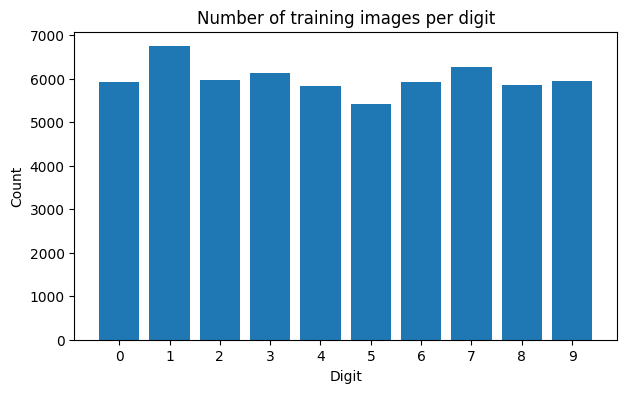

In [4]:
counts = np.bincount(y_train)
for digit in range(10):
    print("Digit", digit, ":", counts[digit], "images")

plt.figure(figsize = (7, 4))
plt.bar(class_names, counts)
plt.title("Number of training images per digit")
plt.xlabel("Digit")
plt.ylabel("Count")
plt.show()

**Observation:** every digit has roughly the same number of images, so the dataset is balanced and accuracy is a fair measure for this problem.

## 5. Sample images

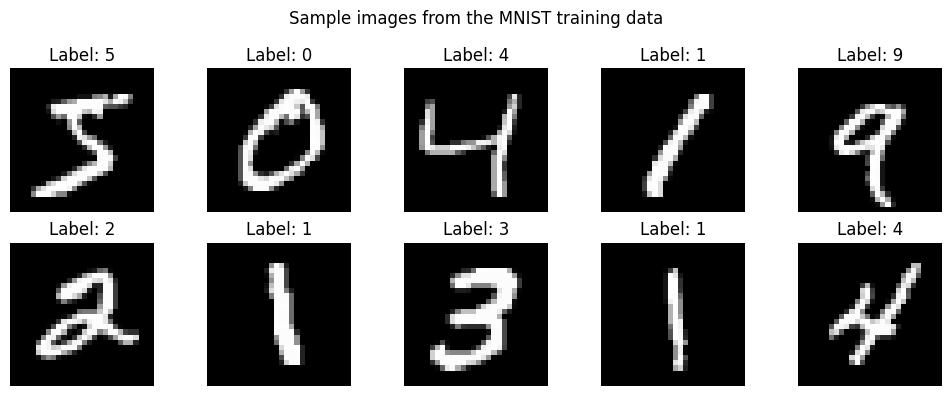

In [5]:
plt.figure(figsize = (10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap = 'gray')
    plt.title("Label: " + str(y_train[i]))
    plt.axis('off')
plt.suptitle("Sample images from the MNIST training data")
plt.tight_layout()
plt.show()

## 6. Preprocessing - Normalization

In [6]:
# pixel values 0-255 are changed to 0-1
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Pixel values now go from", x_train.min(), "to", x_train.max())

Pixel values now go from 0.0 to 1.0


## 7. Preprocessing - Adding the channel dimension

In [7]:
# CNN needs the shape (samples, height, width, channels)
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


## 8. Preprocessing - Labels

In [8]:
print("First 10 labels:", y_train[:10])

First 10 labels: [5 0 4 1 9 2 1 3 1 4]


**Decision:** the labels are already whole numbers from 0 to 9, so no one-hot encoding is needed. The loss function `sparse_categorical_crossentropy` works directly with these integer labels.

## Choosing the CNN approach

A normal neural network treats an image as a long list of numbers and loses the shape. A **CNN** keeps the shape of the image. The convolution layer slides small filters over the image to find patterns such as edges and curves, the pooling layer makes the image smaller, and the dense layers use these patterns to decide the digit.

## 9. Building the CNN model

In [9]:
model = Sequential([
    Input(shape = (28, 28, 1)),
    Conv2D(32, (3, 3), activation = 'relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation = 'relu'),
    Dense(10, activation = 'softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

**What each layer does**

- **Conv2D (32 filters, 3 x 3, ReLU):** finds patterns like edges and curves. ReLU keeps only the positive values.
- **MaxPooling2D (2 x 2):** keeps the strongest value from every 2 x 2 block, so the image becomes half the size.
- **Flatten:** changes the 2D result into one long 1D list.
- **Dense (64, ReLU):** a fully connected layer that combines the patterns.
- **Dense (10, softmax):** 10 outputs, one for each digit, which give the probability of each digit.

## 10. Compiling the model

In [10]:
model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

## 11. Training the model

In [11]:
# validation_split = 0.1 keeps 10% of the training data aside to check the model after every epoch
history = model.fit(x_train, y_train, epochs = 5, validation_split = 0.1)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 32s 18ms/step - accuracy: 0.9467 - loss: 0.1814 - val_accuracy: 0.9798 - val_loss: 0.0715
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 30s 18ms/step - accuracy: 0.9810 - loss: 0.0624 - val_accuracy: 0.9822 - val_loss: 0.0648
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 30s 18ms/step - accuracy: 0.9877 - loss: 0.0405 - val_accuracy: 0.9837 - val_loss: 0.0644
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 40s 17ms/step - accuracy: 0.9919 - loss: 0.0272 - val_accuracy: 0.9837 - val_loss: 0.0661
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.9944 - loss: 0.0185 - val_accuracy: 0.9812 - val_loss: 0.0803


## 12. Training and validation accuracy

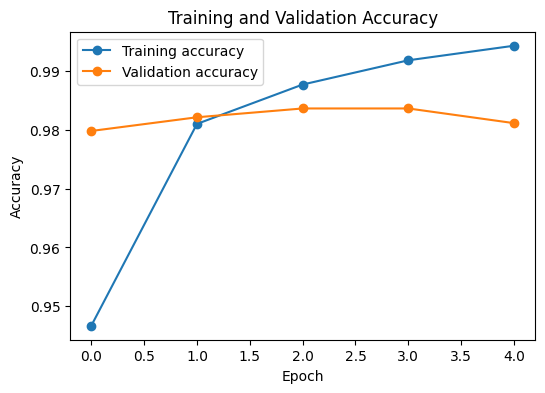

In [12]:
plt.figure(figsize = (6, 4))
plt.plot(history.history['accuracy'], marker = 'o', label = 'Training accuracy')
plt.plot(history.history['val_accuracy'], marker = 'o', label = 'Validation accuracy')
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

## 13. Training and validation loss

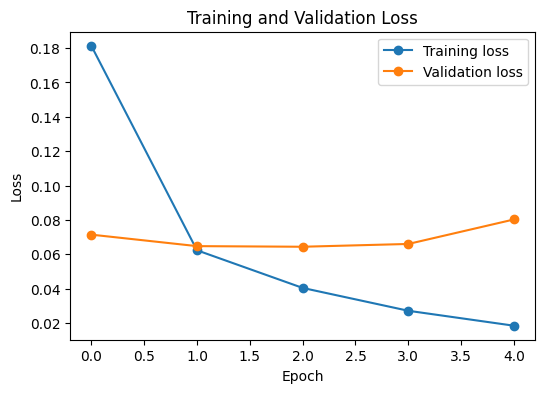

In [13]:
plt.figure(figsize = (6, 4))
plt.plot(history.history['loss'], marker = 'o', label = 'Training loss')
plt.plot(history.history['val_loss'], marker = 'o', label = 'Validation loss')
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

## 14. Evaluating the model on the test data

In [14]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test loss    :", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9794 - loss: 0.0683
Test loss    : 0.0683
Test accuracy: 0.9794


## 15. Predicting the test images

In [15]:
probabilities = model.predict(x_test)
predicted = probabilities.argmax(axis = 1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


## 16. Sample actual and predicted labels

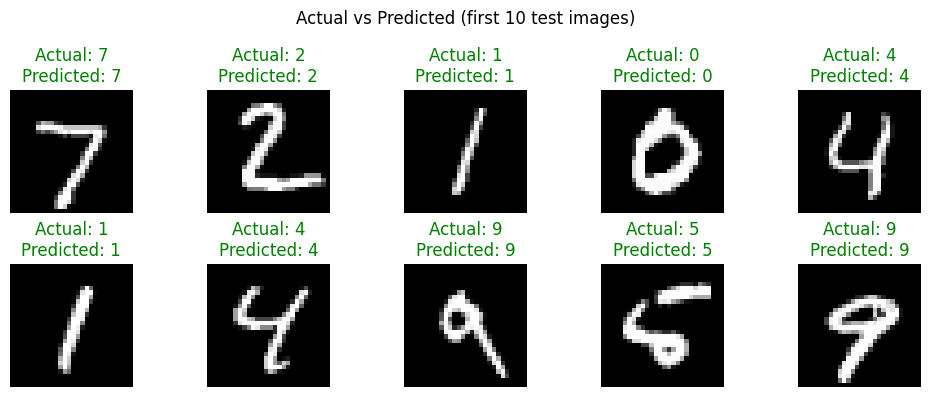

In [16]:
plt.figure(figsize = (10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap = 'gray')
    colour = 'green' if predicted[i] == y_test[i] else 'red'
    plt.title("Actual: " + str(y_test[i]) + "\nPredicted: " + str(predicted[i]), color = colour)
    plt.axis('off')
plt.suptitle("Actual vs Predicted (first 10 test images)")
plt.tight_layout()
plt.show()

**Note:** a green title means the model predicted correctly and a red title means it predicted wrongly.

## 17. Counting correct and incorrect predictions

In [17]:
wrong_index = np.where(predicted != y_test)[0]
correct_count = len(y_test) - len(wrong_index)

print("Correct predictions  :", correct_count, "out of", len(y_test))
print("Incorrect predictions:", len(wrong_index), "out of", len(y_test))

Correct predictions  : 9794 out of 10000
Incorrect predictions: 206 out of 10000


## 18. Looking at the wrong predictions

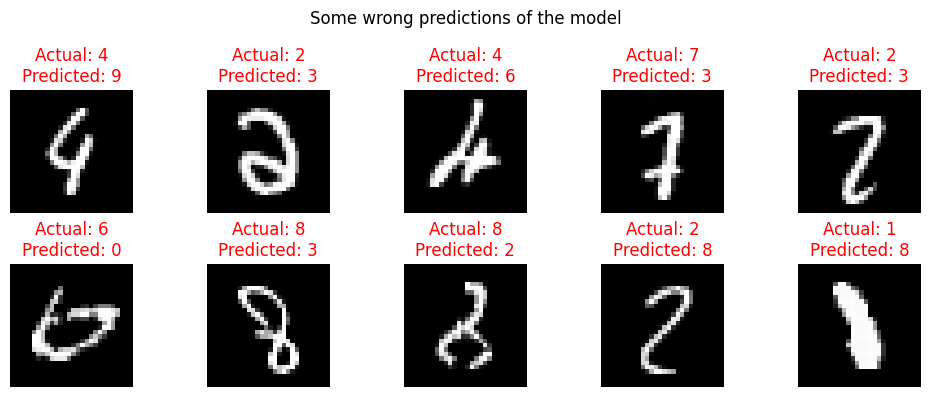

In [18]:
plt.figure(figsize = (10, 4))
for i, index in enumerate(wrong_index[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[index].reshape(28, 28), cmap = 'gray')
    plt.title("Actual: " + str(y_test[index]) + "\nPredicted: " + str(predicted[index]), color = 'red')
    plt.axis('off')
plt.suptitle("Some wrong predictions of the model")
plt.tight_layout()
plt.show()

**Observation:** the wrongly predicted digits are usually written in an unclear or unusual way, so even a person may find some of them confusing.

## 19. Prediction probabilities for one image

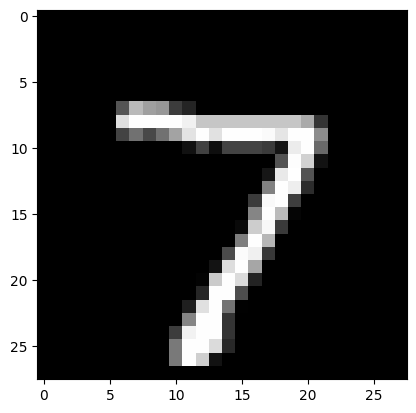

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Predicted digit: 7

Digit 0: 0.00%
Digit 1: 0.00%
Digit 2: 0.00%
Digit 3: 0.00%
Digit 4: 0.00%
Digit 5: 0.00%
Digit 6: 0.00%
Digit 7: 100.00%
Digit 8: 0.00%
Digit 9: 0.00%


In [19]:
image = x_test[0]
plt.imshow(image.reshape(28, 28), cmap = 'gray')
plt.show()

prediction = model.predict(image.reshape(1, 28, 28, 1))
print("Predicted digit:", prediction.argmax())
print()

for digit, probability in enumerate(prediction[0]):
    print(f"Digit {digit}: {probability:.2%}")

## 20. Result in simple words

In [20]:
train_acc = history.history['accuracy'][-1]
val_acc = history.history['val_accuracy'][-1]

print(f"The model got {correct_count} out of {len(y_test)} test images right, which is {test_accuracy:.2%}.")
print(f"After the last epoch the training accuracy was {train_acc:.2%} and the validation accuracy was {val_acc:.2%}.")

if train_acc - test_accuracy > 0.02:
    print("Training accuracy is clearly higher than test accuracy, so the model is memorising the training data a little (overfitting).")
else:
    print("Training, validation and test accuracy are close to each other, so the model is not overfitting much.")

The model got 9794 out of 10000 test images right, which is 97.94%.
After the last epoch the training accuracy was 99.44% and the validation accuracy was 98.12%.
Training, validation and test accuracy are close to each other, so the model is not overfitting much.


# Part B - Streamlit Application: Student Marks Calculator

## App description

- **Purpose:** quickly calculate the result of a student from the marks of five subjects.
- **User inputs:** student name and marks (out of 100) for Mathematics, Science, English, Social Studies and Computer Science.
- **Processing:** total marks, percentage, grade and pass / fail (pass mark is 35 in every subject).
- **Output:** total, percentage and grade, a PASS / FAIL message, the subjects that need improvement, and a bar chart of the marks.
- **Invalid input handling:** empty name, name with digits or symbols, and all marks being 0 show an error or warning message. The marks box only accepts values from 0 to 100.

## 21. Installing Streamlit

In [21]:
!pip install streamlit -q

## 22. Writing the Streamlit app to a file (app.py)

In [22]:
%%writefile app.py
import streamlit as st
import pandas as pd

SUBJECTS = ["Mathematics", "Science", "English", "Social Studies", "Computer Science"]
MAX_MARKS = 100       # maximum marks for each subject
PASS_MARKS = 35       # minimum marks needed in each subject to pass


def get_grade(percentage):
    """Return the grade for a given percentage."""
    if percentage >= 90:
        return "A+"
    elif percentage >= 80:
        return "A"
    elif percentage >= 70:
        return "B"
    elif percentage >= 60:
        return "C"
    elif percentage >= 50:
        return "D"
    else:
        return "F"


def calculate_result(marks):
    """Return total, percentage, grade and the failed subjects."""
    total = sum(marks)
    percentage = total / (len(marks) * MAX_MARKS) * 100
    grade = get_grade(percentage)
    failed_subjects = [SUBJECTS[i] for i in range(len(marks)) if marks[i] < PASS_MARKS]
    return total, percentage, grade, failed_subjects


# title and instructions
st.title("Student Marks Calculator")
st.write("Enter the student name and the marks (out of 100) for each subject, then click **Calculate Result**.")
st.write("Pass mark is " + str(PASS_MARKS) + " in every subject.")

# user inputs
name = st.text_input("Student name")

marks = []
left, right = st.columns(2)
for i, subject in enumerate(SUBJECTS):
    column = left if i % 2 == 0 else right
    with column:
        value = st.number_input(subject + " (out of " + str(MAX_MARKS) + ")",
                                min_value = 0, max_value = MAX_MARKS, value = 0, step = 1)
        marks.append(value)

# process only when the button is clicked
if st.button("Calculate Result"):
    # invalid input handling
    if name.strip() == "":
        st.error("Please enter the student name.")
    elif not name.replace(" ", "").isalpha():
        st.error("The name should contain only letters.")
    elif sum(marks) == 0:
        st.warning("All marks are 0. Please enter the marks first.")
    else:
        total, percentage, grade, failed_subjects = calculate_result(marks)

        # output
        st.subheader("Result for " + name.strip().title())

        col1, col2, col3 = st.columns(3)
        col1.metric("Total", str(total) + " / " + str(len(SUBJECTS) * MAX_MARKS))
        col2.metric("Percentage", str(round(percentage, 2)) + " %")
        col3.metric("Grade", grade)

        if len(failed_subjects) == 0:
            st.success("Result: PASS")
        else:
            st.error("Result: FAIL - needs improvement in " + ", ".join(failed_subjects))

        # bar chart of the marks
        chart_data = pd.DataFrame({"Marks": marks}, index = SUBJECTS)
        st.bar_chart(chart_data)

Writing app.py


## 23. Running the Streamlit app

**On your own computer (recommended, this is where the screenshots are taken):** save `app.py`, open the terminal in the same folder and run

`streamlit run app.py`

**On Colab (optional):** the next cell starts the app and gives a link. Open the link and use the password printed by the first line.

In [ ]:
!curl -s ipv4.icanhazip.com
!npm install -s localtunnel
!streamlit run app.py &>/content/logs.txt & npx localtunnel --port 8501

34.178.128.249
⠙your url is: https://late-needles-visit.loca.lt
